In [1]:
import numpy as np

def mae_manual(y_true, y_pred):
    abs_diff = np.abs(y_true - y_pred)
    mae = abs_diff.mean()
    return mae

y_true = np.array([100, 200, 300])
y_pred = np.array([90, 230, 280])

test_mae = mae_manual(y_true, y_pred)

print(test_mae)

20.0


In [2]:
assert np.allclose(mae_manual(y_true, y_pred), 20)
assert np.allclose(mae_manual(y_true, y_true), 0)

In [3]:
def rmse_manual(y_true, y_pred):
    error = y_true - y_pred
    se = error ** 2
    mse = se.mean()
    rmse = np.sqrt(mse)
    return rmse

y_true = np.array([100, 200, 300])
y_pred = np.array([90, 230, 280])

assert np.allclose(rmse_manual(y_true, y_pred), np.sqrt(1400/3))
assert np.allclose(rmse_manual(y_true, y_true), 0)

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

assert np.allclose(test_mae, mean_absolute_error(y_true, y_pred))
assert np.allclose(rmse_manual(y_true, y_pred), np.sqrt(mean_squared_error(y_true, y_pred)))


In [5]:
from sklearn.linear_model import LinearRegression
import pandas as pd

df = pd.read_csv('../../01-intro/1.9 Bike Sharing/data/day.csv')
df['dteday'] = pd.to_datetime(df['dteday'])
df = df.sort_values('dteday')
X_calendar = df[["season","yr","mnth","holiday","weekday","workingday"]]

y = df["cnt"]
X_train = X_calendar.iloc[:511]
X_val = X_calendar.iloc[511:511+109]
X_test = X_calendar.iloc[511+109:]
y_train = df["cnt"].iloc[:511]
y_val = df["cnt"].iloc[511:511+109]

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_val)

bike_mae = mae_manual(y_val, y_pred)
print(bike_mae)

assert np.allclose(bike_mae, 1124.77840589107)


1124.7784058910688


In [6]:
bike_rmse = rmse_manual(y_val, y_pred)
print(bike_rmse)

assert np.allclose(bike_rmse, np.sqrt(mean_squared_error(y_val, y_pred)))
assert bike_rmse >= bike_mae

1300.4543998614956


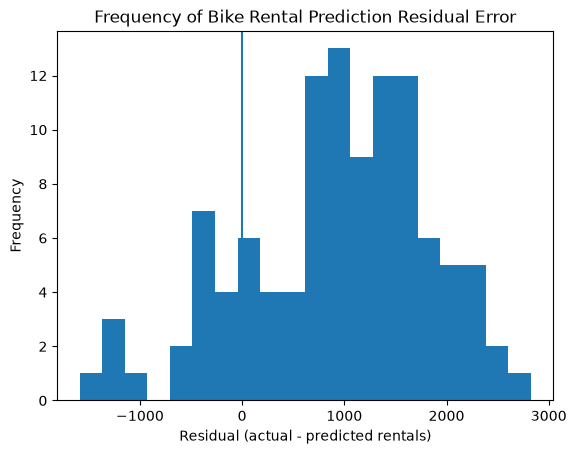

In [7]:
import matplotlib.pyplot as plt

residual = y_val - y_pred

plt.hist(residual, bins=20)
plt.xlabel("Residual (actual - predicted rentals)")
plt.ylabel("Frequency")

plt.title("Frequency of Bike Rental Prediction Residual Error")

plt.axvline()
plt.show()

In [8]:
mean_signed_error = residual.mean()
underpredictions = (residual > 0).sum()
overpredictions = (residual < 0).sum()

print(mean_signed_error, underpredictions, overpredictions)

assert np.allclose(underpredictions + overpredictions, 109)

931.6766065706322 89 20


In [9]:
train_baseline = y_train.mean()
train_baseline_pred = np.full(109, train_baseline)

train_baseline_mae = mae_manual(y_val, train_baseline_pred)
train_baseline_rmse = rmse_manual(y_val, train_baseline_pred)

print(train_baseline_mae, train_baseline_rmse)

assert np.allclose(train_baseline_mae, 2950.8161726422377)

2950.8161726422377 3071.075384901727


In [10]:
seasonal_baseline = y_train.groupby(X_train["season"]).mean()
seasonal_pred = X_val["season"].map(seasonal_baseline)

seasonal_mae = mae_manual(y_val, seasonal_pred)
seasonal_rmse = rmse_manual(y_val, seasonal_pred)

print(seasonal_mae, seasonal_rmse)

assert np.allclose(seasonal_mae, 2235.467828136698)
assert seasonal_pred.shape[0] == 109


2235.467828136698 2383.353514467134


In [11]:
comparison = {
    "model": ["Train Baseline", "Seasonal Baseline", "LinearRegression"],
    "mae": [train_baseline_mae, seasonal_mae, bike_mae],
    "rmse": [train_baseline_rmse, seasonal_rmse, bike_rmse]
}

comparison_df = pd.DataFrame(comparison).sort_values(by="mae")

print(comparison_df)

               model          mae         rmse
2   LinearRegression  1124.778406  1300.454400
1  Seasonal Baseline  2235.467828  2383.353514
0     Train Baseline  2950.816173  3071.075385


In [12]:
assert seasonal_pred.notna().all()

# Day 12 — Prediction Error Metrics and Model Evaluation

## 1. Objective

The objective of Day 12 was to implement Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) manually, verify both implementations against scikit-learn, analyze the distribution of prediction errors, and compare a trained linear regression model against two simpler baselines.

This experiment builds on the Bike Sharing regression model developed on Day 11.

## 2. Dataset and Experimental Setup

**Dataset:** UCI Bike Sharing Dataset (`day.csv`)

**Prediction target:** `cnt` — total daily bike rentals.

**Prediction objective:** Predict tomorrow's total bike rentals using calendar information available the previous day.

The dataset contains 731 daily observations from 2011–2012.

### Chronological Split

| Dataset | Observations |
|---|---:|
| Training | 511 |
| Validation | 109 |
| Test | 111 |

The dataset was split chronologically rather than randomly to better simulate predictions on future observations.

The test dataset was preserved and was not used for model evaluation or selection during Day 12.

### Features

The linear regression model used six calendar features:

- `season`
- `yr`
- `mnth`
- `holiday`
- `weekday`
- `workingday`

Observed weather information was excluded because it would not be available when predicting tomorrow's demand. The variables `casual` and `registered` were excluded because they directly reveal the target (`casual + registered = cnt`).

## 3. Manual Metric Implementations

### Mean Absolute Error (MAE)

MAE calculates the average absolute difference between actual and predicted values.

\[
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
\]

MAE is expressed in the same units as the prediction target.

### Root Mean Squared Error (RMSE)

RMSE calculates the square root of the average squared prediction error.

\[
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
\]

RMSE penalizes large prediction errors more heavily than MAE.

### Implementation Verification

Both metric functions were implemented manually using NumPy and tested against scikit-learn's `mean_absolute_error()` and `mean_squared_error()`.

The synthetic test used:

- Actual values: `[100, 200, 300]`
- Predictions: `[90, 230, 280]`

**Results:**

| Metric | Expected Result | Observed Result |
|---|---:|---:|
| MAE | 20.00 | 20.00 |
| RMSE | 21.6025 | 21.6025 |

Additional tests confirmed that perfect predictions produce zero error.

The manual implementations agreed with the corresponding scikit-learn calculations within floating-point tolerance.

These tests verify the functions on the tested inputs but do not establish correctness for every possible input. Additional edge-case testing would be necessary for production use.

## 4. Validation Results

The linear regression model was fitted using only the training observations and evaluated using the 109 validation observations.

| Metric | Linear Regression |
|---|---:|
| Validation MAE | 1,124.78 |
| Validation RMSE | 1,300.45 |
| Mean Signed Error | +931.68 |

RMSE was approximately 15.6% higher than MAE, indicating that larger errors have a meaningful influence on the model's overall evaluation.

However, the difference between RMSE and MAE alone does not prove the existence of extreme outliers.

## 5. Residual Distribution Analysis

Residuals were calculated using:

`residual = actual - predicted`

A histogram with 20 bins was created to visualize the frequency distribution of prediction errors.

### Observations

- Positive residuals represent underpredictions.
- Negative residuals represent overpredictions.
- The histogram showed substantially more positive than negative residuals.
- The distribution was not symmetric around zero.

### Directional Error Analysis

| Statistic | Result |
|---|---:|
| Mean signed error | +931.68 |
| Underpredictions | 89 |
| Overpredictions | 20 |
| Total validation observations | 109 |

The model underpredicted demand on approximately **81.7%** of validation days.

The positive mean signed error indicates that the model underestimated actual rental demand by approximately 932 rentals per day on average.

This systematic underprediction could be operationally significant for a bike-sharing company because underestimating demand may result in insufficient bike availability.

Possible explanations include changes in rental demand over time, inadequate feature representation, or changes in the relationship between calendar variables and demand. These explanations require further investigation.

## 6. Baseline Versus Model Comparison

Three approaches were evaluated using the same chronological validation observations.

**Training-mean baseline:** Predicts the average daily rental demand observed in the training dataset.

**Seasonal baseline:** Predicts the average training rental demand for the validation observation's season.

**Linear regression:** Learns coefficients for six calendar features using the training dataset.

### Results

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| Training-mean baseline | 2,950.82 | 3,071.08 |
| Seasonal baseline | 2,235.47 | 2,383.35 |
| Linear regression | **1,124.78** | **1,300.45** |

### Performance Improvement

Compared with the seasonal baseline, linear regression achieved:

- Approximately **49.7% lower MAE**.
- Approximately **45.4% lower RMSE**.

The regression model substantially outperformed both baselines according to both error metrics.

The comparison was also organized into a pandas DataFrame using previously computed metric variables, rather than hardcoded numbers, to support reproducible experiment reporting.

## 7. Data Leakage and Evaluation Integrity

Several precautions were taken to prevent data leakage:

1. The regression model was fitted exclusively on training observations.
2. The training-mean baseline was calculated from training targets only.
3. Seasonal averages were calculated using training observations only.
4. Validation targets were used to evaluate predictions, not to construct them.
5. The test dataset remained untouched.

Using validation targets to calculate baseline averages would result in target leakage and invalidate the evaluation.

## 8. Limitations

**Historical dataset:** The dataset represents 2011–2012. Its demand patterns may not generalize to later years because infrastructure, customer behavior, and transportation demand can change.

**Feature representation:** Calendar variables such as season, month, and weekday were represented numerically. This imposes relationships that might not reflect their categorical or cyclical behavior.

**Missing weather forecasts:** Weather strongly influences bike-rental demand, but the current model does not incorporate weather forecasts. Including historical observed weather values as if they were known in advance would introduce training-serving inconsistency.

**Directional prediction bias:** The model systematically underpredicted demand on the validation period, suggesting that its predictions may require further investigation or improvement.

**Limited validation period:** Strong performance on one chronological validation split does not guarantee strong performance on future unseen data.

**Metric robustness:** The manual functions have not yet been hardened against empty arrays, mismatched dimensions, or non-finite input values.

## 9. Engineering Conclusions

This experiment demonstrated that model evaluation requires more than a single accuracy metric.

Key takeaways:

1. MAE measures the average magnitude of prediction errors.
2. RMSE gives greater weight to large prediction errors.
3. Residual distributions reveal patterns that aggregate metrics can hide.
4. Mean signed error helps identify systematic overprediction or underprediction.
5. Simple baselines are essential for determining whether model complexity provides meaningful improvements.
6. Validation integrity depends on separating the data used to estimate model parameters from the data used to evaluate predictions.
7. Reproducibility requires calculated results, consistent experiment settings, and successful execution from a clean notebook state.

**Final conclusion:** Linear regression is the strongest of the three evaluated approaches on the selected validation period, but its directional bias and historical-data limitations should be investigated before considering deployment.

## 10. Next Steps

- Complete a clean-kernel reproducibility check.
- Consider adding explicit input validation to metric functions.
- Investigate prediction bias by time period and season.
- Explore improved calendar feature encoding.
- Preserve the untouched test dataset until model selection is finalized.

**Day 12 status:** Core metric implementation, synthetic testing, scikit-learn verification, residual analysis, and baseline comparison completed. Final clean-kernel reproducibility confirmation remains pending.